<a href="https://colab.research.google.com/github/crd10lop/Modelos-udea-cristian-diez/blob/main/MODELOS2_Aprendizaje_Automatico/LAB_05_02_M%C3%A1quinas_de_Vectores_de_Soporte.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 5 - Parte 2. Máquinas de Vectores de Soporte

In [ ]:
!wget -nc --no-cache -O init.py -q https://raw.githubusercontent.com/jdariasl/Intro_ML_2025/master/init.py
import init; init.init(force_download=False); init.get_weblink()

replicating local resources
replicating Labs resources


In [ ]:
from local.lib.rlxmoocapi import submit, session
import inspect
session.LoginSequence(endpoint=init.endpoint, course_id=init.course_id, lab_id="L05.02", varname="student",session_id="udea.vir.20262.g2");

logging in as cristian.diez@udea.edu.co... please wait
you are registered in the following sessions of this course

     ['udea.vir.20261', 'udea.vir.20262.g2']

and you have explicitly requested session 'udea.vir.20262.g2'.
your grades will be reported in that session

-------------
using course session introml::udea.vir.20262.g2
success!! you are logged in
-------------


In [ ]:
from Labs.commons.utils.lab5 import *
_, dataset = part_2()

Dim de la base de datos original: (2000, 13)


## Ejercicio 1: Limipiar base de datos y completar código

En este ejercicio usaremos la regresión por vectores de soporte para resolver el problema de regresión de la base de datos AirQuality (https://archive.ics.uci.edu/ml/datasets/Air+Quality). Tener en cuenta que vamos a usar solo 2000 muestras.

En primera instancia vamos a transformar la matriz en un dataframe, para poderlo procesar de manera mas sencilla. Se crea una columna por cada variable que obtenemos.

In [ ]:
dataset_df = pd.DataFrame(dataset, columns = [f'col_{c}' for c in range (1,14)])

Para esta base de datos vamos a realizar una limpieza de datos.
Para ello vamos a completar la siguiente función para realizar:
    
1. **Remover** todos los registros cuya variable objetivo es faltante (missing Value). Estos registros están marcados como -200, es decir, donde haya un valor -200 eliminaremos el registro.
2. **imputar los valores perdidos/faltantes** en cada una de las características, vamos a usar el valor medio de la propia característica (estimado con las muestras que si cuentan con información en dicha variable) y lo usaremos para llenar los huecos. (será de utilidad conocer [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html))
3. **Verificar** si quedaron valores faltantes
4. **retornar** X (12 primeras columnas) y Y(la 13 columna).

información de utilidad:

1. Aca puede ser de utilidad revisar la [sesión extra](https://jdariasl.github.io/Intro_ML_2025/Labs/Extra/Basic_Preprocessing_FeatureEngineering.html).
2. Para transformar columnas de pandas a arreglos de numpy se puede usar `.iloc` / `.loc` y . `.values`, por ejemplo  para devolver una matriz con los valores de las primeras dos columnas es posible hacerlo asi: `dataset_df.iloc[: , 0:2].values` o `dataset_df.loc[: , ['col_1', 'col_2']].values`
3. Para cambiar valores faltantes, podemos usar la [librería sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html)

In [ ]:
# ejercicio de codigo
def clean_data(df):
    """función que limpia el dataset y obtiene X y Y

    df: es un pandas dataframe

    retorna:
    X: una matriz numpy con los valores a usar como conjunto de datos
       de entrada
    Y una matriz numpy con los valores usados como conjunto de datos
       de salida

    """

    # se copia el df para evitar cambios sobre el objeto
    database = df.copy()

    ##Verificar
    pct_valores_faltantes = (database==-200).mean()
    print(",".join([f"% VF en {a}: {pct_valores_faltantes[a]*100:.2f}% " for a in pct_valores_faltantes.index]))

    # identificar y remover del data frame las muestras cuya salida es un valor faltante
    database = database[database.iloc[:,12] != -200]

    # Imprimir el número de muestras removidas
    print(f"\nSe removieron {df.shape[0] - database.shape[0]} muestras")

    print ("\nDim de la base de datos sin las muestras con variable de salida perdido "+ str(np.shape(database)))

    ##Imputar los valores de las características en el dataframe que tienen datos faltantes
    imputer = SimpleImputer(missing_values=-200, strategy='mean')
    database = pd.DataFrame(imputer.fit_transform(database), columns=database.columns)

    print ("Imputación finalizada.\n")

    ##Verificar
    pct_valores_faltantes = (database==-200).mean()

    print(",".join([f"% VF en {a}: {pct_valores_faltantes[a]*100:.2f}% " for a in pct_valores_faltantes.index]))

    if(pct_valores_faltantes.max() != 0):
        print ("Hay valores perdidos")
    else:
        print ("No hay valores perdidos en la base de datos. Ahora se puede procesar")

    X = database.iloc[:,0:12].values
    Y = database.iloc[:,12:13].values
    return (X,Y)

**Registra tu solución en línea**

In [ ]:
student.submit_task(namespace=globals(), task_id='T1');

Ahora usemos la función para tener nuestras variables X, Y

In [ ]:
X,Y = clean_data(dataset_df)

% VF en col_1: 20.00% ,% VF en col_2: 2.05% ,% VF en col_3: 54.30% ,% VF en col_4: 2.05% ,% VF en col_5: 2.05% ,% VF en col_6: 20.15% ,% VF en col_7: 2.05% ,% VF en col_8: 20.15% ,% VF en col_9: 2.05% ,% VF en col_10: 2.05% ,% VF en col_11: 2.05% ,% VF en col_12: 2.05% ,% VF en col_13: 2.05% 

Se removieron 41 muestras

Dim de la base de datos sin las muestras con variable de salida perdido (1959, 13)
Imputación finalizada.

% VF en col_1: 0.00% ,% VF en col_2: 0.00% ,% VF en col_3: 0.00% ,% VF en col_4: 0.00% ,% VF en col_5: 0.00% ,% VF en col_6: 0.00% ,% VF en col_7: 0.00% ,% VF en col_8: 0.00% ,% VF en col_9: 0.00% ,% VF en col_10: 0.00% ,% VF en col_11: 0.00% ,% VF en col_12: 0.00% ,% VF en col_13: 0.00% 
No hay valores perdidos en la base de datos. Ahora se puede procesar


### Ejercicio 2: Experimentar SVM para regresión

Ahora vamos a crear una función para experimentar con la maquina de soporte vectorial. Para ello debemos hacer lo siguiente:
1. Revisar la documentación de la clase de objetos que vamos a usar (ver  [sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html).
2. Vamos a evaluar el efecto de tres hiperparámetros del SVR: kernel,  gamma y el parámetro de regularización, por lo tanto debemos comprender la relación con el modelo y su efecto.
3. El número máximo de iteraciones debe ser ajustado a 200
4. Utilizar la metodología cross-validation con 4 folds.
5. Usar normalización de datos estandar implementada por sklearn
6. Extraer los vectores de soporte (observe los *atributos* del modelo SVR de sklearn). Recuerde que estos atributos son accesibles, una vez el modelo es entrenado
7. Utilizar la métrica para calcular el MAPE (usar sklearn).


In [ ]:
#ejercicio de código
def experiementarSVR(x, y, kernels, gammas,params_reg):
    """función que realizar experimentos sobre una SVM para regresión

    x: numpy.Array, con las muestras del problema
    y: numpy.Array, con la variable objetivo
    kernels: List[str], lista con valores a pasar
        a sklearn correspondiente al kernel de la SVM
    gammas: List[float], lista con los valores a pasar a
        sklearn correspondientes al valor de los coeficientes para usar en el
        kernel
    params_reg: List[float], lista con los valores a pasar a
        sklearn para ser usados como parámetro de regularización

    retorna: pd.Dataframe con las siguientes columnas:
        - 3 columnas con los tres parametros: kernel, gamma, param de regularizacion
        - porcentaje de error absoluto medio en el cojunto test (promedio de los 4 folds)
        - intervalo de confianza del porcentaje de error absoluto medio en el cojunto test
            (desviacion estandar de los 4 folds)
        - # de Vectores de Soporte promedio para los 4 folds
        - % de Vectores de Soporte promedio para los 4 folds (0 a 100)
    """
    idx = 0
    kf = KFold(n_splits=4)
    # crear una lista con la combinaciones de los elementos de cada list
    kernels_gammas_regs = list(itertools.product(kernels, gammas, params_reg))
    resultados = pd.DataFrame()

    for params in kernels_gammas_regs:
        kernel, gamma, param_reg = params
        print("parametros usados", params) # puede usar para ver los params
        errores_test = []
        pct_support_vectors = []
        num_support_vectors = []
        for train_index, test_index in kf.split(x):

            X_train, X_test = x[train_index], x[test_index]
            y_train, y_test = y[train_index], y[test_index]
            # normalizar los datos
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_train)
            X_test = scaler.transform(X_test)

            #Definir y entrenar el modelo
            svr = SVR(kernel=kernel, gamma=gamma, C=param_reg, max_iter=200)
            svr.fit(X_train, y_train.ravel())

            # Validación del modelo
            ypred = svr.predict(X=X_test)

            # MAPE de prueba
            errores_test.append(mean_absolute_percentage_error(y_test.ravel(), ypred))

            # Encontrar el número de vectores de soporte y el calcular el porcentaje que representan

            num_vs = svr.support_vectors_.shape[0]
            pct_vs = num_vs / X_train.shape[0] * 100


            pct_support_vectors.append(pct_vs)
            num_support_vectors.append(num_vs)

        resultados.loc[idx,'kernel'] = kernel
        resultados.loc[idx,'gamma'] = gamma
        resultados.loc[idx,'param_reg'] = param_reg
        resultados.loc[idx,'error de prueba (promedio)'] = np.mean(errores_test)
        resultados.loc[idx,'error de prueba (intervalo de confianza)'] = np.std(errores_test)
        resultados.loc[idx,'# de vectores de soporte'] = np.mean(num_support_vectors)
        resultados.loc[idx,'% de vectores de soporte'] = np.mean(pct_support_vectors)

        idx+=1
    return (resultados)

**Registra tu solución en línea**

In [ ]:
student.submit_task(namespace=globals(), task_id='T2');

Para entrenar vamos a ignorar las dos primeras variables, estas corresponden a valores de fechas.

In [ ]:
# vamos a realizar los experimentos
import itertools
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, mean_absolute_percentage_error
from sklearn.multiclass import OneVsOneClassifier
resultadosSVR = experiementarSVR(x =X[:,2:],y=Y,
                                 kernels=['linear', 'rbf'],
                                 gammas = [0.01,0.1],
                                 params_reg = [0.1, 1.0,10]
                                )

parametros usados ('linear', 0.01, 0.1)
parametros usados ('linear', 0.01, 1.0)
parametros usados ('linear', 0.01, 10)
parametros usados ('linear', 0.1, 0.1)
parametros usados ('linear', 0.1, 1.0)
parametros usados ('linear', 0.1, 10)
parametros usados ('rbf', 0.01, 0.1)
parametros usados ('rbf', 0.01, 1.0)
parametros usados ('rbf', 0.01, 10)
parametros usados ('rbf', 0.1, 0.1)
parametros usados ('rbf', 0.1, 1.0)
parametros usados ('rbf', 0.1, 10)


In [ ]:
# ver los 5 primeros resultados
resultadosSVR.sort_values('error de prueba (promedio)',ascending=True).head(5)

,kernel,gamma,param_reg,error de prueba (promedio),error de prueba (intervalo de confianza),# de vectores de soporte,% de vectores de soporte
8,rbf,0.01,10.0,0.049432,0.005736,29.00,1.973877
7,rbf,0.01,1.0,0.054073,0.011585,55.25,3.760553
3,linear,0.10,0.1,0.063900,0.012843,65.00,4.424246
0,linear,0.01,0.1,0.063900,0.012843,65.00,4.424246
10,rbf,0.10,1.0,0.068657,0.018409,66.25,4.509107


In [ ]:
#@title Pregunta Abierta
#@markdown ¿Cual es el objetivo de las las funciones kernel? Contestar dentro del contexto de las máquinas de sporte vectorial
respuesta = "El kernel calcula la similitud entre muestras como si estuvieran en un espacio de mayor dimensión, sin calcular esa transformación explícitamente (truco del kernel). Así la SVM puede encontrar fronteras o funciones de regresión no lineales usando un modelo lineal en ese nuevo espacio." #@param {type:"string"}

In [ ]:
#@title Pregunta Abierta
#@markdown Existe alguna relación entre el porcentaje de vectores de soporte y error esperado?
respuesta = "Sí. En SVR los vectores de soporte son las muestras que quedan fuera del margen (tubo épsilon). Un porcentaje alto de vectores de soporte suele indicar que el modelo no se ajusta bien a muchos datos o que es más complejo, lo que tiende a asociarse con mayor error y peor generalización. No es una regla exacta, pero sí una tendencia." #@param {type:"string"}

Para analizar los resultados vamos a crear dos graficas para el mejor modelo encontrado:
1. vamos a graficar en el eje x el valor real, en el eje y el valor predicho. El modelo ideal deberia ser una recta que recuerda la identidad
2. en el eje x vamos a dejar un valor incremental y con colores vamos a diferenciar entre el valor real y el valor predicho



Mejor modelo: rbf 0.01 10.0


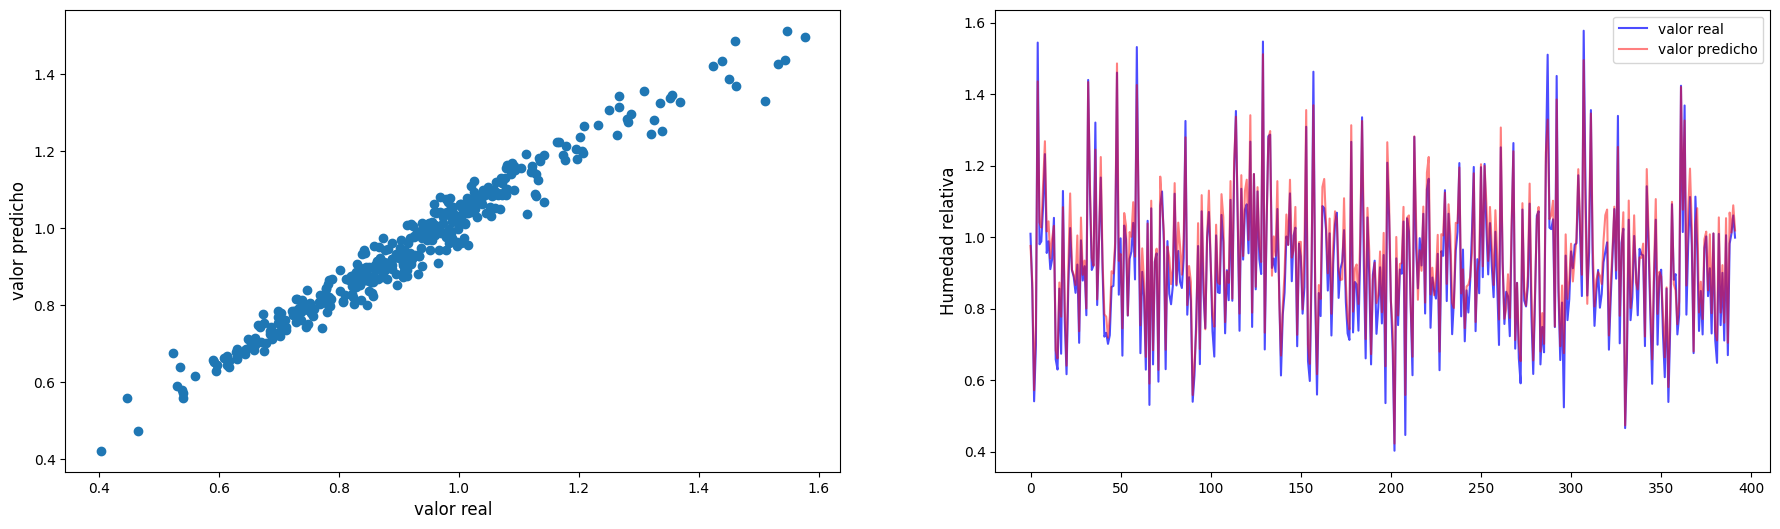

In [ ]:
def predict_svr(X_train, y_train, X_test, kernel, gamma, param_reg):
    """entrena un SVR y retorna las predicciones sobre X_test"""
    svr = SVR(kernel=kernel, gamma=gamma, C=param_reg, max_iter=200)
    svr.fit(X_train, y_train.ravel())
    return svr.predict(X_test)

# mejor modelo encontrado (menor error de prueba)
mejor = resultadosSVR.sort_values('error de prueba (promedio)', ascending=True).iloc[0]
print("Mejor modelo:", mejor['kernel'], mejor['gamma'], mejor['param_reg'])

# dividir el conjunto
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

#predicciones
# OJO: Completar!
Ypred =  predict_svr(X_train,y_train,X_test,
                     kernel = mejor['kernel'], gamma=mejor['gamma'], param_reg=mejor['param_reg'])

# plots

f, ax = plt.subplots(ncols=2, sharex=False, sharey=False, figsize = (22,6))
ax[0].scatter(y_test, Ypred)
ax[0].set_xlabel('valor real', fontdict = {'fontsize': 12})
ax[0].set_ylabel('valor predicho', fontdict = {'fontsize': 12})
ax[1].plot(y_test, label = 'valor real', color = 'b', alpha = 0.7)
ax[1].plot(Ypred, label = 'valor predicho', color = 'r', alpha = 0.5)
ax[1].legend()
ax[1].set_ylabel('Humedad relativa', fontdict = {'fontsize': 12})
plt.show()

In [ ]:
#@title Pregunta Abierta
#@markdown usando las anteriores graficas, ¿como calificaría el modelo de manera cualitativa?.
respuesta = "El modelo es aceptable: los puntos del gráfico real vs predicho siguen aproximadamente la diagonal y la curva predicha sigue la tendencia de la real. Sin embargo, falla en los valores extremos (picos altos y bajos), donde subestima o sobreestima la humedad." #@param {type:"string"}

## Ejercicio 3: Experimentar SVM para clasificación

En este ejercicio vamos a volver a resolver el problema de clasificación de dígitos. Vamos usar solo 5 clases y realizaremos un pre-procesamiento:
1. Mediante PCA reduciremos la dimensionalidad de los datos
2. Vamos a convertir el problema en uno de cuatro clases (diferenciar entre 0, 1, 2 y el resto)

In [ ]:
Xcl, Ycl = load_digits(n_class=5,return_X_y=True)
#--------- preprocesamiento--------------------
pca = PCA(0.99, whiten=True)
Xcl = pca.fit_transform(Xcl)
# cambiar problema de clases
unique, counts  = np.unique(Ycl, return_counts=True)
print("distribución original (claves las etiquetas, valores el número de muestras): \n", dict(zip(unique, counts )))
Ycl = np.where(np.isin(Ycl, [0,1,2]), Ycl, 3)
unique, counts  = np.unique(Ycl, return_counts=True)
print("Nueva distribución  (claves las etiquetas, valores el número de muestras): \n", dict(zip(unique, counts )))

distribución original (claves las etiquetas, valores el número de muestras): 
 {np.int64(0): np.int64(178), np.int64(1): np.int64(182), np.int64(2): np.int64(177), np.int64(3): np.int64(183), np.int64(4): np.int64(181)}
Nueva distribución  (claves las etiquetas, valores el número de muestras): 
 {np.int64(0): np.int64(178), np.int64(1): np.int64(182), np.int64(2): np.int64(177), np.int64(3): np.int64(364)}


Ahora vamos a crear la función para experimentar con la máquina de soporte vectorial. Los parámetros de la prueba y sus requerimientos se listan a continuación:

1. Revisar la documentación correspondiente al modelo [sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html#sklearn.svm.SVC)
2. Realizaremos pruebas para ajustar tres hiperparámetros del SVC: kernel,  gamma y el parametro de regularización.
3. El número máximo de iteraciones será ajustado a 500
4. Seleccionar una metodología de cross-validation con 4 folds adecuada para la distribución de datos.
5. Usar normalización de datos estandar implementada por sklearn
6. Extraer los vectores de soporte (observe los *atributos* del modelo SVC de sklearn). Recuerde que estos atributos son accesibles una vez el modelo es entrenado
7. vamos a probar la dos estragegias multiclase básicas del SVC:
    - One Vs One (ver [link](https://scikit-learn.org/stable/modules/generated/sklearn.multiclass.OneVsOneClassifier.html))
    - One Vs Rest (ver [link](https://scikit-learn.org/stable/modules/generated/sklearn.multiclass.OneVsRestClassifier.html))
8. Utilizar como medida de desempeño el score de exactitud de sklearn.

In [ ]:
#ejercicio de código
def experiementarSVC(x, y, kernels, gammas,params_reg, estrategia = 'ovo'):
    """función que realizar experimentos sobre un SVM para clasificación

    x: numpy.Array, con los datos de entrada del problema
    y: numpy.Array, con la variable objetivo
    kernels: List[str], lista con valores a pasar
        a sklearn correspondiente al kernel de la SVM
    gammas: List[float], lista con los valores a pasar a
        sklean correspondiente el valor de los coeficientes para usar en el
        kernel
    params_reg: List[float], lista con los valores a a pasar a
        sklearn para ser usados como parametro de regularización
    estrategia: str, valor que puede ser ovo (para one vs one) o ovr
        (para one vs rest)

    retorna: pd.Dataframe con las siguientes columnas:
        - 3 columnas con los tres parametros: kernel, gamma, param de regularizacion
        - estrategia de clasificación (ovo o ovr)
        - Error en el conjunto de entrenamiento (promedio de los 4 folds)
        - Error en el conjunto de test (promedio de los 4 folds)
        - % de Vectores de Soporte promedio para los 4 folds (0 a 100)
    """
    import itertools
    from sklearn.model_selection import StratifiedKFold
    from sklearn.preprocessing import StandardScaler
    from sklearn.svm import SVC
    from sklearn.multiclass import OneVsOneClassifier, OneVsRestClassifier
    from sklearn.metrics import accuracy_score

    idx = 0
    kf = StratifiedKFold(n_splits=4)
    # crear una lista con la combinaciones de los elementos de cada list
    kernels_gammas_regs = list(itertools.product(kernels, gammas, params_reg))
    resultados = pd.DataFrame()

    for params in kernels_gammas_regs:
        kernel, gamma, param_reg = params
        print("parametros usados", params) # puede usar para ver los params
        errores_train = []
        errores_test = []
        pct_support_vectors = []

        for train_index, test_index in kf.split(x,y):
            X_train, X_test = x[train_index], x[test_index]
            y_train, y_test = y[train_index], y[test_index]
            # normalizar los datos
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_train)
            X_test = scaler.transform(X_test)

            #Instanciar y entrenar el modelo con los hiperparámetros adecuados
            base = SVC(kernel=kernel, gamma=gamma, C=param_reg, max_iter=500)
            if estrategia == 'ovo':
                svm = OneVsOneClassifier(base)
            else:
                svm = OneVsRestClassifier(base)
            svm.fit(X_train, y_train)


            # calculo de errores
            y_train_pred = svm.predict(X_train)
            y_test_pred = svm.predict(X_test)

            # error y pct de vectores de soporte
            errores_train.append(1 - accuracy_score(y_true = y_train, y_pred = y_train_pred))
            errores_test.append(1 - accuracy_score(y_true = y_test, y_pred = y_test_pred))

            # Calcular el porcentaje de vectores de soporte. Tenga en cuenta que las estrategias
            # OVO y OVR implican el entrenamiento de varios modelos. En este caso se debe estimar
            # el promedio de porcentajes de vectores de soporte dentro de los estimadores que hacen parte de
            # la estrategia multiclase y promediarlos.
            pct_vs = np.mean([est.support_.shape[0] / est.shape_fit_[0] * 100
                              for est in svm.estimators_])

            pct_support_vectors.append(pct_vs)

        resultados.loc[idx,'kernel'] = kernel
        resultados.loc[idx,'gamma'] = gamma
        resultados.loc[idx,'param_reg'] = param_reg
        resultados.loc[idx,'estrategia'] = estrategia
        resultados.loc[idx,'error de entrenamiento'] = np.mean(errores_train)
        resultados.loc[idx,'error de prueba'] = np.mean(errores_test)
        resultados.loc[idx,'% de vectores de soporte'] = np.mean(pct_support_vectors)
        idx+=1
    return (resultados)

**Registra tu solución en línea**

In [ ]:
student.submit_task(namespace=globals(), task_id='T3');

Veamos la estrategia OVR

In [ ]:
# vamos a realizar los experimentos
resultadosSVC_ovr = experiementarSVC(x = Xcl,y=Ycl,
                                 kernels=['linear', 'rbf'],
                                 gammas = [0.01,0.1],
                                 params_reg = [0.001, 0.01,0.1, 1.0,10],
                                estrategia = 'ovr')

parametros usados ('linear', 0.01, 0.001)
parametros usados ('linear', 0.01, 0.01)
parametros usados ('linear', 0.01, 0.1)
parametros usados ('linear', 0.01, 1.0)
parametros usados ('linear', 0.01, 10)
parametros usados ('linear', 0.1, 0.001)
parametros usados ('linear', 0.1, 0.01)
parametros usados ('linear', 0.1, 0.1)
parametros usados ('linear', 0.1, 1.0)
parametros usados ('linear', 0.1, 10)
parametros usados ('rbf', 0.01, 0.001)
parametros usados ('rbf', 0.01, 0.01)
parametros usados ('rbf', 0.01, 0.1)
parametros usados ('rbf', 0.01, 1.0)
parametros usados ('rbf', 0.01, 10)
parametros usados ('rbf', 0.1, 0.001)
parametros usados ('rbf', 0.1, 0.01)
parametros usados ('rbf', 0.1, 0.1)
parametros usados ('rbf', 0.1, 1.0)
parametros usados ('rbf', 0.1, 10)


In [ ]:
# ver los mejores modelos
resultadosSVC_ovr.sort_values('error de prueba', ascending=True).head(5)

,kernel,gamma,param_reg,estrategia,error de entrenamiento,error de prueba,% de vectores de soporte
14,rbf,0.01,10.0,ovr,0.000000,0.018874,24.149326
13,rbf,0.01,1.0,ovr,0.000370,0.034390,31.363125
2,linear,0.01,0.1,ovr,0.007028,0.051032,12.014300
7,linear,0.10,0.1,ovr,0.007028,0.051032,12.014300
3,linear,0.01,1.0,ovr,0.003328,0.053260,9.165612


Ahora vamos a ver la estrategia OVO

In [ ]:
# vamos a realizar los experimentos
resultadosSVC_ovo = experiementarSVC(x = Xcl,y=Ycl,
                                 kernels=['linear', 'rbf'],
                                 gammas = [0.01,0.1],
                                 params_reg = [0.001, 0.01,0.1, 1.0,10],
                                estrategia = 'ovo')

parametros usados ('linear', 0.01, 0.001)
parametros usados ('linear', 0.01, 0.01)
parametros usados ('linear', 0.01, 0.1)
parametros usados ('linear', 0.01, 1.0)
parametros usados ('linear', 0.01, 10)
parametros usados ('linear', 0.1, 0.001)
parametros usados ('linear', 0.1, 0.01)
parametros usados ('linear', 0.1, 0.1)
parametros usados ('linear', 0.1, 1.0)
parametros usados ('linear', 0.1, 10)
parametros usados ('rbf', 0.01, 0.001)
parametros usados ('rbf', 0.01, 0.01)
parametros usados ('rbf', 0.01, 0.1)
parametros usados ('rbf', 0.01, 1.0)
parametros usados ('rbf', 0.01, 10)
parametros usados ('rbf', 0.1, 0.001)
parametros usados ('rbf', 0.1, 0.01)
parametros usados ('rbf', 0.1, 0.1)
parametros usados ('rbf', 0.1, 1.0)
parametros usados ('rbf', 0.1, 10)


In [ ]:
# ver los mejores modelos
resultadosSVC_ovo.sort_values('error de prueba', ascending=True).head(5)

,kernel,gamma,param_reg,estrategia,error de entrenamiento,error de prueba,% de vectores de soporte
14,rbf,0.01,10.0,ovo,0.00000,0.009980,31.844755
2,linear,0.01,0.1,ovo,0.00148,0.024420,12.374389
7,linear,0.10,0.1,ovo,0.00148,0.024420,12.374389
13,rbf,0.01,1.0,ovo,0.00037,0.026603,37.684341
9,linear,0.10,10.0,ovo,0.00000,0.031077,10.766595


In [ ]:
#@title Pregunta Abierta
#@markdown Según el tipo de problema (enfocarse en la distribución de clases) ¿La métrica usada es la adecuada? ¿Cual otra métrica del modulo de sklearn podría ser usada?
respuesta = "No del todo. Las clases están desbalanceadas (la clase 3 'resto' tiene cerca del doble de muestras que las clases 0, 1 y 2), así que la exactitud puede verse alta aunque el modelo falle en las clases pequeñas. Sería mejor usar balanced_accuracy_score o f1_score con average='macro' de sklearn.metrics." #@param {type:"string"}

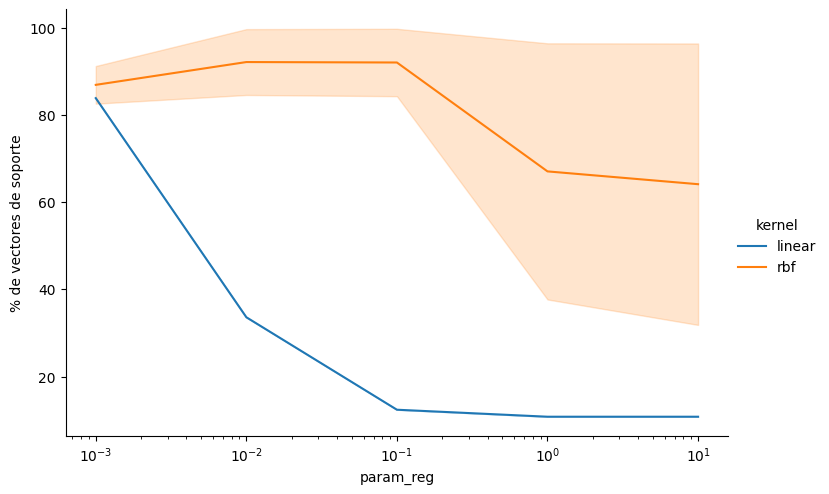

In [ ]:
# ver la relación de parametro de regularización y los vectores de soporte
import seaborn as sns
ax= sns.relplot(data = resultadosSVC_ovo, x = 'param_reg', y = '% de vectores de soporte', kind = 'line', hue ='kernel', aspect = 1.5)
ax.set(xscale="log")
plt.show()